# Experiment 032: seed-matched warm-start analysis

The direct comparison checks whether replacing the shared seed-0 warm-up changes
the old wsft endpoints. The derived tables then compare the corrected wsft family
with plain MC-SFT and the SFT-to-GRPO pipeline. The probe bundle is descriptive.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.stats import _read_preds, align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import tier_of
from scripts.s32_wsft import arm_tag, historical_tag, pipeline_tag, plain_tag

RES = ROOT / 'results'
FIG = ROOT / 'analysis/figures/032_1'
FIG.mkdir(parents=True, exist_ok=True)
SCALES = ('B05', 'B15', 'B3', 'B7')
LABELS = {'B05': '0.5B', 'B15': '1.5B', 'B3': '3B', 'B7': '7B'}

for scale in SCALES:
    for seed in (1, 2):
        assert (RES / arm_tag(scale, seed) / '032_arm_complete.json').exists(), \
            f'{scale} seed {seed} is not complete'


## Registered comparisons


In [2]:
def rows(tag, condition):
    return _read_preds(RES / tag / f'{condition}_preds.jsonl')


def paired(new_rows, ref_rows, tier=None):
    new_rows, ref_rows = align_pred_rows(new_rows, ref_rows)
    if tier is not None:
        keep = [i for i, row in enumerate(new_rows) if tier_of(row['subject']) == tier]
        new_rows = [new_rows[i] for i in keep]
        ref_rows = [ref_rows[i] for i in keep]
    new_correct = [bool(row['correct']) for row in new_rows]
    ref_correct = [bool(row['correct']) for row in ref_rows]
    delta, lo, hi = paired_delta_ci(ref_correct, new_correct)
    n01 = sum(not a and b for a, b in zip(ref_correct, new_correct))
    n10 = sum(a and not b for a, b in zip(ref_correct, new_correct))
    return {'reference_acc': sum(ref_correct) / len(ref_correct),
            'new_acc': sum(new_correct) / len(new_correct),
            'delta': delta, 'ci_low': lo, 'ci_high': hi,
            'p_raw': mcnemar_exact(n01, n10), 'n': len(new_correct)}


def category(result, adjusted_p):
    if abs(result['delta']) >= 0.02 and adjusted_p < 0.05:
        return 'material improvement' if result['delta'] > 0 else 'material decline'
    if result['ci_low'] > -0.02 and result['ci_high'] < 0.02:
        return 'equivalent'
    return 'inconclusive'


def adjust(rows_list, family):
    selected = [row for row in rows_list if row['family'] == family and row['inferential']]
    adjusted = holm([row['p_raw'] for row in selected])
    for row, value in zip(selected, adjusted):
        row['holm_p'] = value
        row['category'] = category(row, value)


direct = []
for scale in SCALES:
    for seed in (1, 2):
        for endpoint, tier in (('overall', None), ('hard', 'hard')):
            result = paired(rows(arm_tag(scale, seed), 'sft'),
                            rows(historical_tag(scale, seed), 'sft'), tier=tier)
            direct.append({'scale': scale, 'seed': seed, 'endpoint': endpoint,
                           'family': f'direct_{endpoint}', 'inferential': True, **result})
for family in ('direct_overall', 'direct_hard'):
    adjust(direct, family)
for endpoint in ('overall', 'hard'):
    for scale in SCALES:
        selected = [row for row in direct
                    if row['endpoint'] == endpoint and row['scale'] == scale]
        for row, value in zip(selected, holm([row['p_raw'] for row in selected])):
            row['per_scale_holm_p'] = value

derived = []
for scale in SCALES:
    for seed in (0, 1, 2):
        wsft = historical_tag(scale, 0) if seed == 0 else arm_tag(scale, seed)
        inferential = seed in (1, 2)
        comparisons = {
            'D1': (plain_tag(scale, seed), 'sft'),
            'D2': (pipeline_tag(scale, seed), 'grpo'),
        }
        for name, (reference, condition) in comparisons.items():
            for endpoint, tier in (('overall', None), ('hard', 'hard')):
                result = paired(rows(wsft, 'sft'), rows(reference, condition), tier=tier)
                derived.append({'comparison': name, 'scale': scale, 'seed': seed,
                                'endpoint': endpoint, 'family': f'{name}_{endpoint}',
                                'inferential': inferential, **result})
for family in ('D1_overall', 'D1_hard', 'D2_overall', 'D2_hard'):
    adjust(derived, family)
for row in derived:
    if not row['inferential']:
        row['holm_p'] = None
        row['category'] = 'descriptive seed 0'

probes = []
for scale in SCALES:
    for seed in (0, 1, 2):
        wsft = historical_tag(scale, 0) if seed == 0 else arm_tag(scale, seed)
        for endpoint, tier in (('overall', None), ('hard', 'hard')):
            result = paired(rows(wsft, 'sft_logprob'),
                            rows(pipeline_tag(scale, seed), 'sft_logprob'), tier=tier)
            result.pop('p_raw')
            probes.append({'scale': scale, 'seed': seed, 'endpoint': endpoint,
                           'scope': 'descriptive bundle', **result})

direct_df = pd.DataFrame(direct)
derived_df = pd.DataFrame(derived)
probe_df = pd.DataFrame(probes)
direct_df[['scale', 'seed', 'endpoint', 'delta', 'holm_p', 'category']]


,scale,seed,endpoint,delta,holm_p,category
0,B05,1,overall,-0.004246,1.000000,equivalent
1,B05,1,hard,0.012626,1.000000,inconclusive
2,B05,2,overall,-0.001062,1.000000,equivalent
3,B05,2,hard,-0.012626,1.000000,inconclusive
4,B15,1,overall,-0.009554,0.912665,inconclusive
5,B15,1,hard,-0.007576,1.000000,inconclusive
6,B15,2,overall,0.002123,1.000000,equivalent
7,B15,2,hard,-0.022727,1.000000,inconclusive
8,B3,1,overall,-0.007962,1.000000,equivalent
9,B3,1,hard,-0.015152,1.000000,inconclusive


## Direct replacement sensitivity


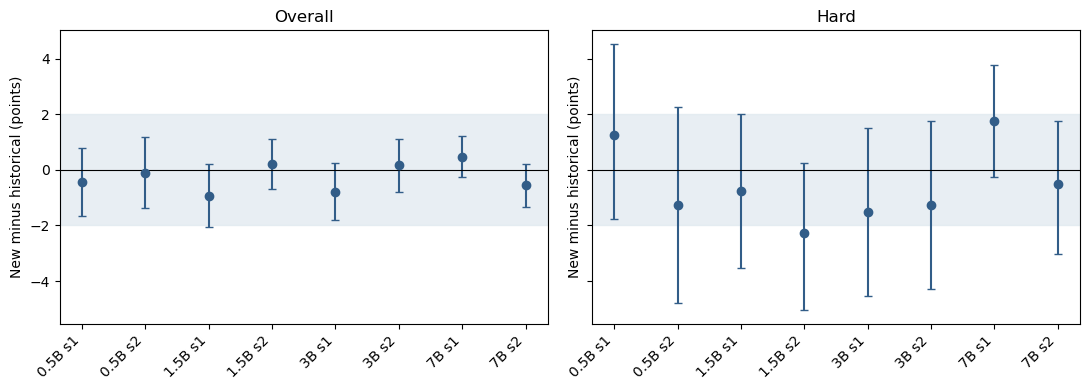

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, endpoint in zip(axes, ('overall', 'hard')):
    frame = direct_df[direct_df.endpoint == endpoint].copy()
    frame['label'] = frame.apply(lambda row: f"{LABELS[row.scale]} s{row.seed}", axis=1)
    x = np.arange(len(frame))
    y = frame.delta.to_numpy() * 100
    lo = (frame.delta - frame.ci_low).to_numpy() * 100
    hi = (frame.ci_high - frame.delta).to_numpy() * 100
    ax.errorbar(x, y, yerr=[lo, hi], fmt='o', color='#325d88', capsize=3)
    ax.axhspan(-2, 2, color='#dfe8ef', alpha=.7)
    ax.axhline(0, color='black', linewidth=.8)
    ax.set_xticks(x, frame.label, rotation=45, ha='right')
    ax.set_title(endpoint.capitalize())
    ax.set_ylabel('New minus historical (points)')
fig.tight_layout()
fig.savefig(FIG / 'direct_replacement_deltas.png', dpi=170, bbox_inches='tight')
plt.show()


## Corrected method comparison


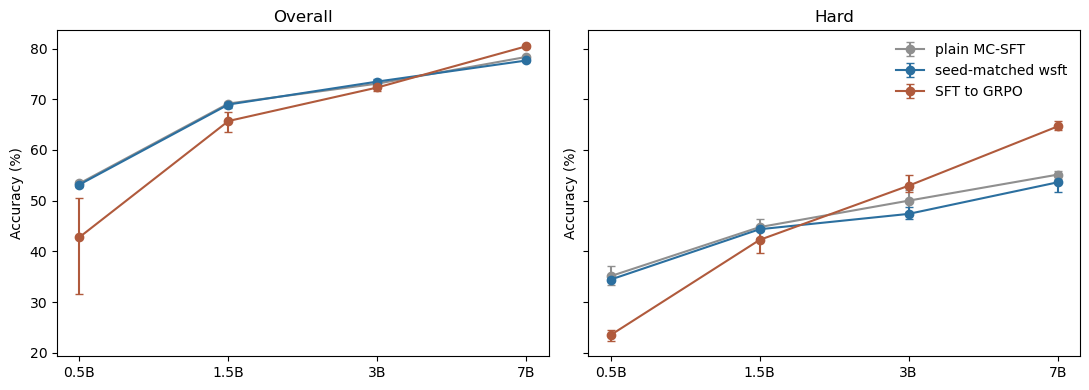

In [4]:
method_rows = []
for scale in SCALES:
    for seed in (0, 1, 2):
        specs = {
            'plain MC-SFT': (plain_tag(scale, seed), 'sft'),
            'seed-matched wsft': (historical_tag(scale, 0), 'sft') if seed == 0
                                 else (arm_tag(scale, seed), 'sft'),
            'SFT to GRPO': (pipeline_tag(scale, seed), 'grpo'),
        }
        for method, (tag, condition) in specs.items():
            current = rows(tag, condition)
            for endpoint, tier in (('overall', None), ('hard', 'hard')):
                selected = current if tier is None else [row for row in current
                                                         if tier_of(row['subject']) == tier]
                method_rows.append({'scale': scale, 'seed': seed, 'method': method,
                                    'endpoint': endpoint,
                                    'accuracy': sum(bool(row['correct']) for row in selected) /
                                                len(selected)})
method_df = pd.DataFrame(method_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {'plain MC-SFT': '#8f8f8f', 'seed-matched wsft': '#2b6f9f',
          'SFT to GRPO': '#b05a3c'}
for ax, endpoint in zip(axes, ('overall', 'hard')):
    frame = method_df[method_df.endpoint == endpoint]
    for method, color in colors.items():
        grouped = frame[frame.method == method].groupby('scale').accuracy
        means = grouped.mean().reindex(SCALES)
        lows = grouped.min().reindex(SCALES)
        highs = grouped.max().reindex(SCALES)
        x = np.arange(len(SCALES))
        ax.errorbar(x, means * 100,
                    yerr=[(means - lows) * 100, (highs - means) * 100],
                    marker='o', capsize=3, label=method, color=color)
    ax.set_xticks(np.arange(len(SCALES)), [LABELS[scale] for scale in SCALES])
    ax.set_title(endpoint.capitalize())
    ax.set_ylabel('Accuracy (%)')
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'corrected_method_comparison.png', dpi=170, bbox_inches='tight')
plt.show()


## Descriptive probe bundle


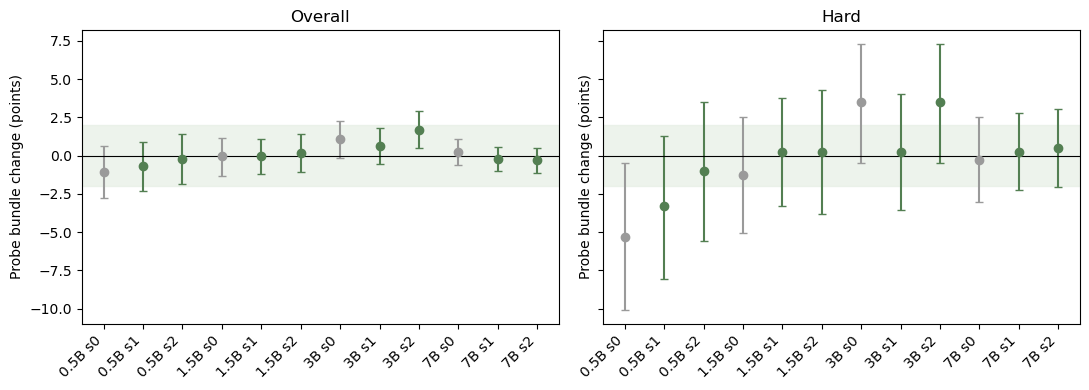

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, endpoint in zip(axes, ('overall', 'hard')):
    frame = probe_df[probe_df.endpoint == endpoint].copy()
    frame['label'] = frame.apply(lambda row: f"{LABELS[row.scale]} s{row.seed}", axis=1)
    x = np.arange(len(frame))
    y = frame.delta.to_numpy() * 100
    lo = (frame.delta - frame.ci_low).to_numpy() * 100
    hi = (frame.ci_high - frame.delta).to_numpy() * 100
    colors = ['#9a9a9a' if seed == 0 else '#537f52' for seed in frame.seed]
    for i in range(len(frame)):
        ax.errorbar(x[i], y[i], yerr=[[lo[i]], [hi[i]]], fmt='o',
                    color=colors[i], capsize=3)
    ax.axhspan(-2, 2, color='#e6eee4', alpha=.7)
    ax.axhline(0, color='black', linewidth=.8)
    ax.set_xticks(x, frame.label, rotation=45, ha='right')
    ax.set_title(endpoint.capitalize())
    ax.set_ylabel('Probe bundle change (points)')
fig.tight_layout()
fig.savefig(FIG / 'probe_change_from_start.png', dpi=170, bbox_inches='tight')
plt.show()


## Exact values


In [6]:
direct_df.to_csv(FIG / 'direct_pairs.csv', index=False)
derived_df.to_csv(FIG / 'derived_pairs.csv', index=False)
probe_df.to_csv(FIG / 'probe_pairs.csv', index=False)
method_df.to_csv(FIG / 'method_endpoints.csv', index=False)

def common_reading(frame, family):
    categories = frame[(frame.family == family) & frame.inferential].category.tolist()
    if len(categories) == 8 and len(set(categories)) == 1 and categories[0] != 'inconclusive':
        return categories[0]
    return 'mixed or inconclusive, report arm by arm'


summary = {
    'binding': len(direct_df) == 16 and len(derived_df[derived_df.inferential]) == 32,
    'direct_common': {family: common_reading(direct_df, family)
                      for family in ('direct_overall', 'direct_hard')},
    'derived_common': {family: common_reading(derived_df, family)
                       for family in ('D1_overall', 'D1_hard', 'D2_overall', 'D2_hard')},
    'direct_pairs': direct,
    'derived_pairs': derived,
    'probe_pairs': probes,
    'scope': {
        'direct': '032 seeds 1-2 against the historical shared-source arms, Holm across eight',
        'D1': 'seed-matched wsft against plain MC-SFT p8, seeds 1-2 inferential',
        'D2': 'seed-matched wsft against SFT-to-GRPO, seeds 1-2 inferential',
        'D3': 'descriptive bundle comparison including merge representation and MMLU SFT',
        'seed0': 'historical and descriptive in derived tables',
    },
}
with open(RES / '032_comparison_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=float)
print('saved', RES / '032_comparison_summary.json')


saved /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/results/032_comparison_summary.json


## Cross-referenced conclusion


7 of the 8 direct overall pairs are equivalent and remaining 1.5B seed 1 pair is unconvincing. This means the shared seed-0 warm-up did not change the overall wsft result, although all hard-tier direct pairs remain unconvincing. The corrected wsft family still stays close to plain MC-SFT and does not show a consistent advantage. Against SFT-to-GRPO the result remains scale-dependent: wsft is higher at 0.5B and 1.5B, mixed at 3B, and lower at 7B, especially on hard questions. The descriptive probe changes range from -3.3 to +3.5 points, so they do not support one common direction.
